## Vessel Route Following, Recovery, and Crossing Behavior (Flag 5)

### Dataset Overview
The main table contains one target cargo-vessel voyage plus surrounding commercial AIS-like traffic defining a structured northbound lane and expected turn branch. It provides local and geographic coordinates, timestamp, course, speed, traffic role, and movement phase.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Analyze how the vessel navigates within a structured shipping corridor and identify any route-following, crossing, or recovery behaviors that distinguish the voyage.

Role: Maritime trajectory analyst


Category: Structured shipping corridor navigation

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display

## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: For which portion of the voyage does the vessel remain aligned with the dominant traffic lane and surrounding commercial traffic?

#### Analysis action

Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.

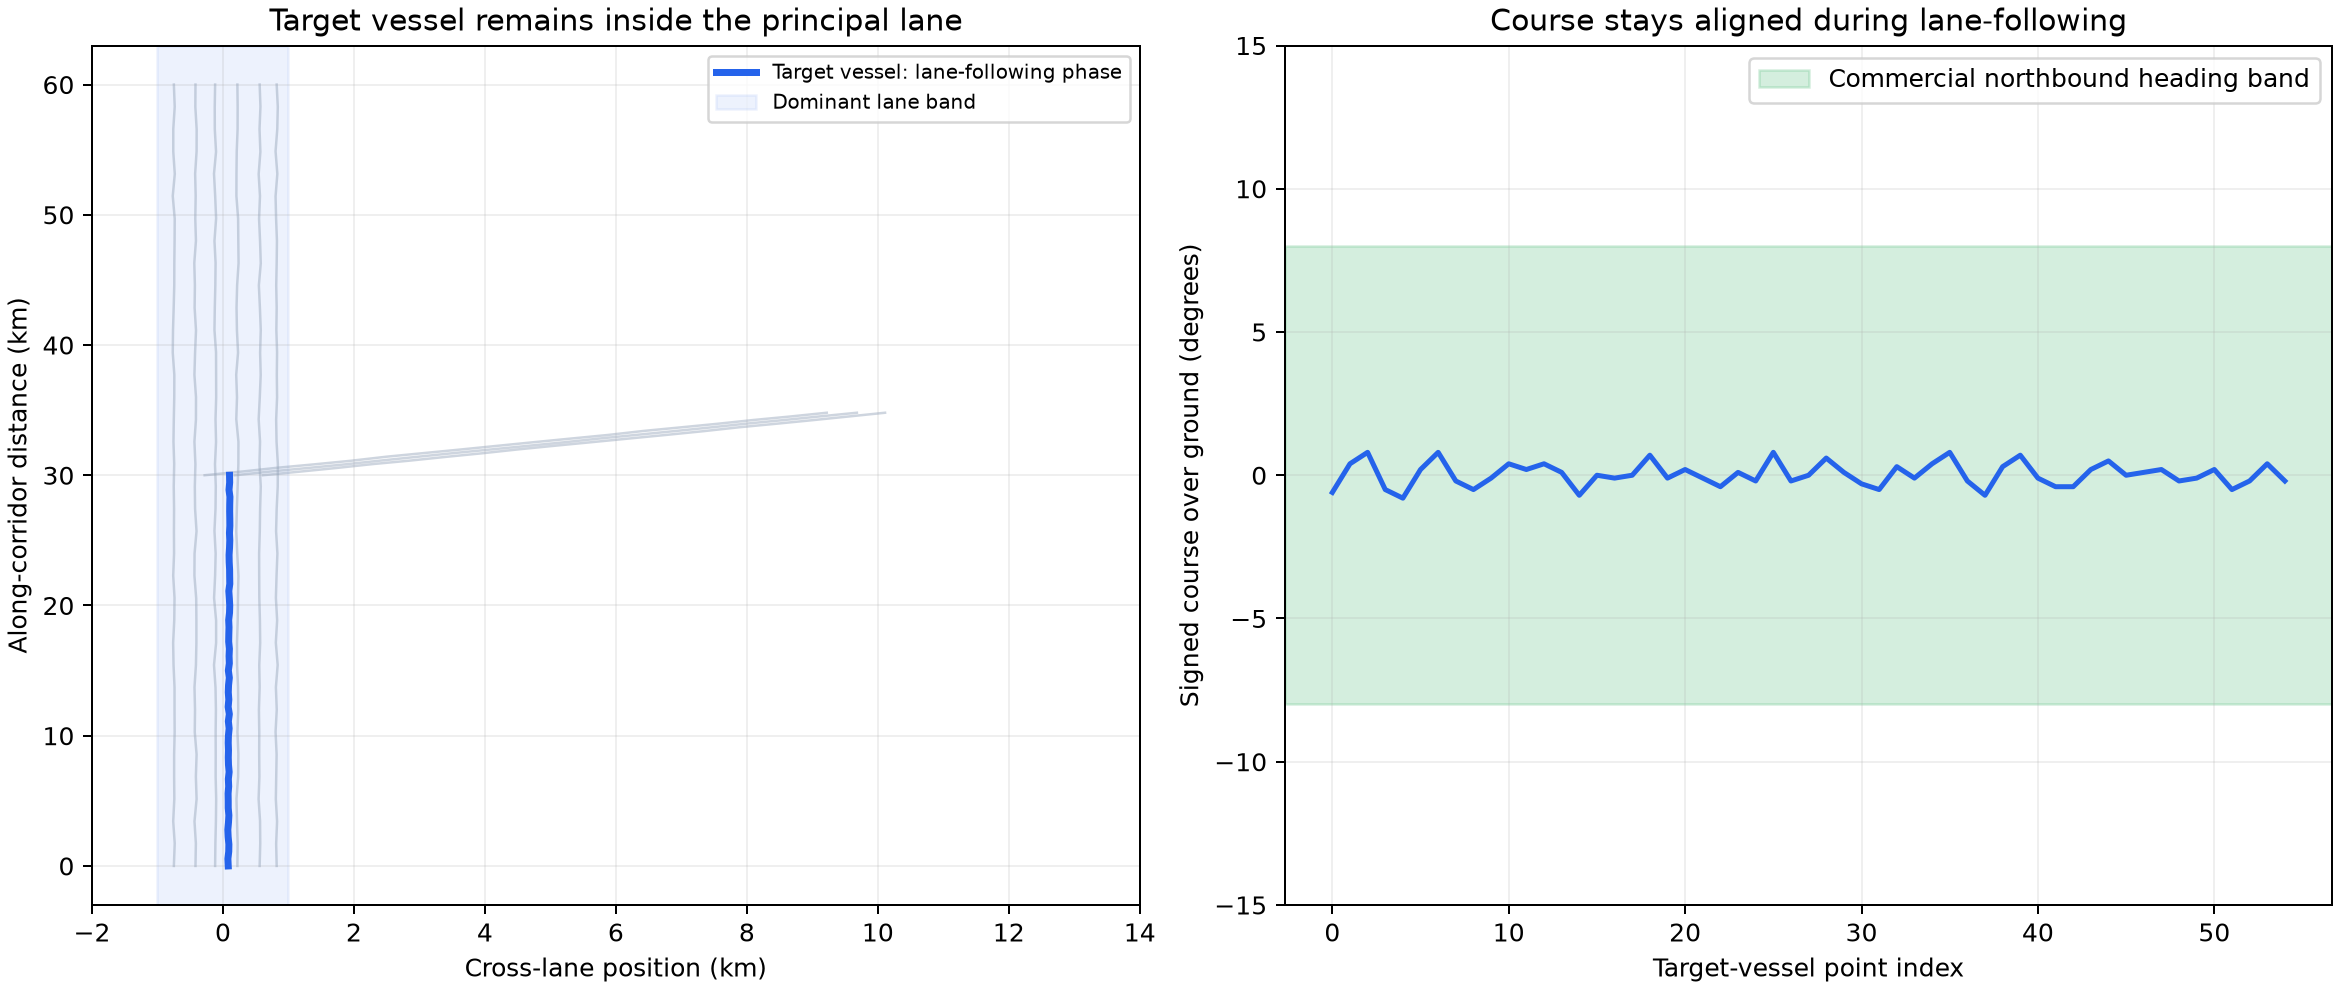

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.copy(); q=d[d.traffic_role.eq('target_vessel')]; print(q.groupby('movement_phase').agg(points=('point_index','size'),course=('cog','median'))); plt.scatter(q.x_km,q.y_km,c=pd.Categorical(q.movement_phase).codes); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/lane_following_alignment.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "trajectory_alignment",
  "insight": "The vessel follows the dominant traffic lane closely for most of the voyage, with its course remaining well aligned with the surrounding commercial traffic flow.",
  "insight_value": {
    "lane_following_share_of_target_points": 0.36,
    "lane_heading_band_degrees": [
      0,
      8
    ]
  },
  "plot": {
    "plot_type": "trajectory_alignment",
    "title": "Lane Following and Course Alignment",
    "file": "visualizations/lane_following_alignment.png",
    "description": "The map compares the target vessel with surrounding commercial tracks, while the course panel shows the target vessel's lane-following segment."
  },
  "question": "For which portion of the voyage does the vessel remain aligned with the dominant traffic lane and surrounding commercial traffic?",
  "actionable_insight": "Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); q=d[d.traffic_role.eq('target_vessel')]; print(q.groupby('movement_phase').agg(points=('point_index','size'),course=('cog','median'))); plt.scatter(q.x_km,q.y_km,c=pd.Categorical(q.movement_phase).codes); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "gps_position",
    "course_over_ground"
  ]
}

### **Question 2**: Does the vessel make the expected turn at the usual point, and if not, how does it recover?

#### Analysis action

Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.

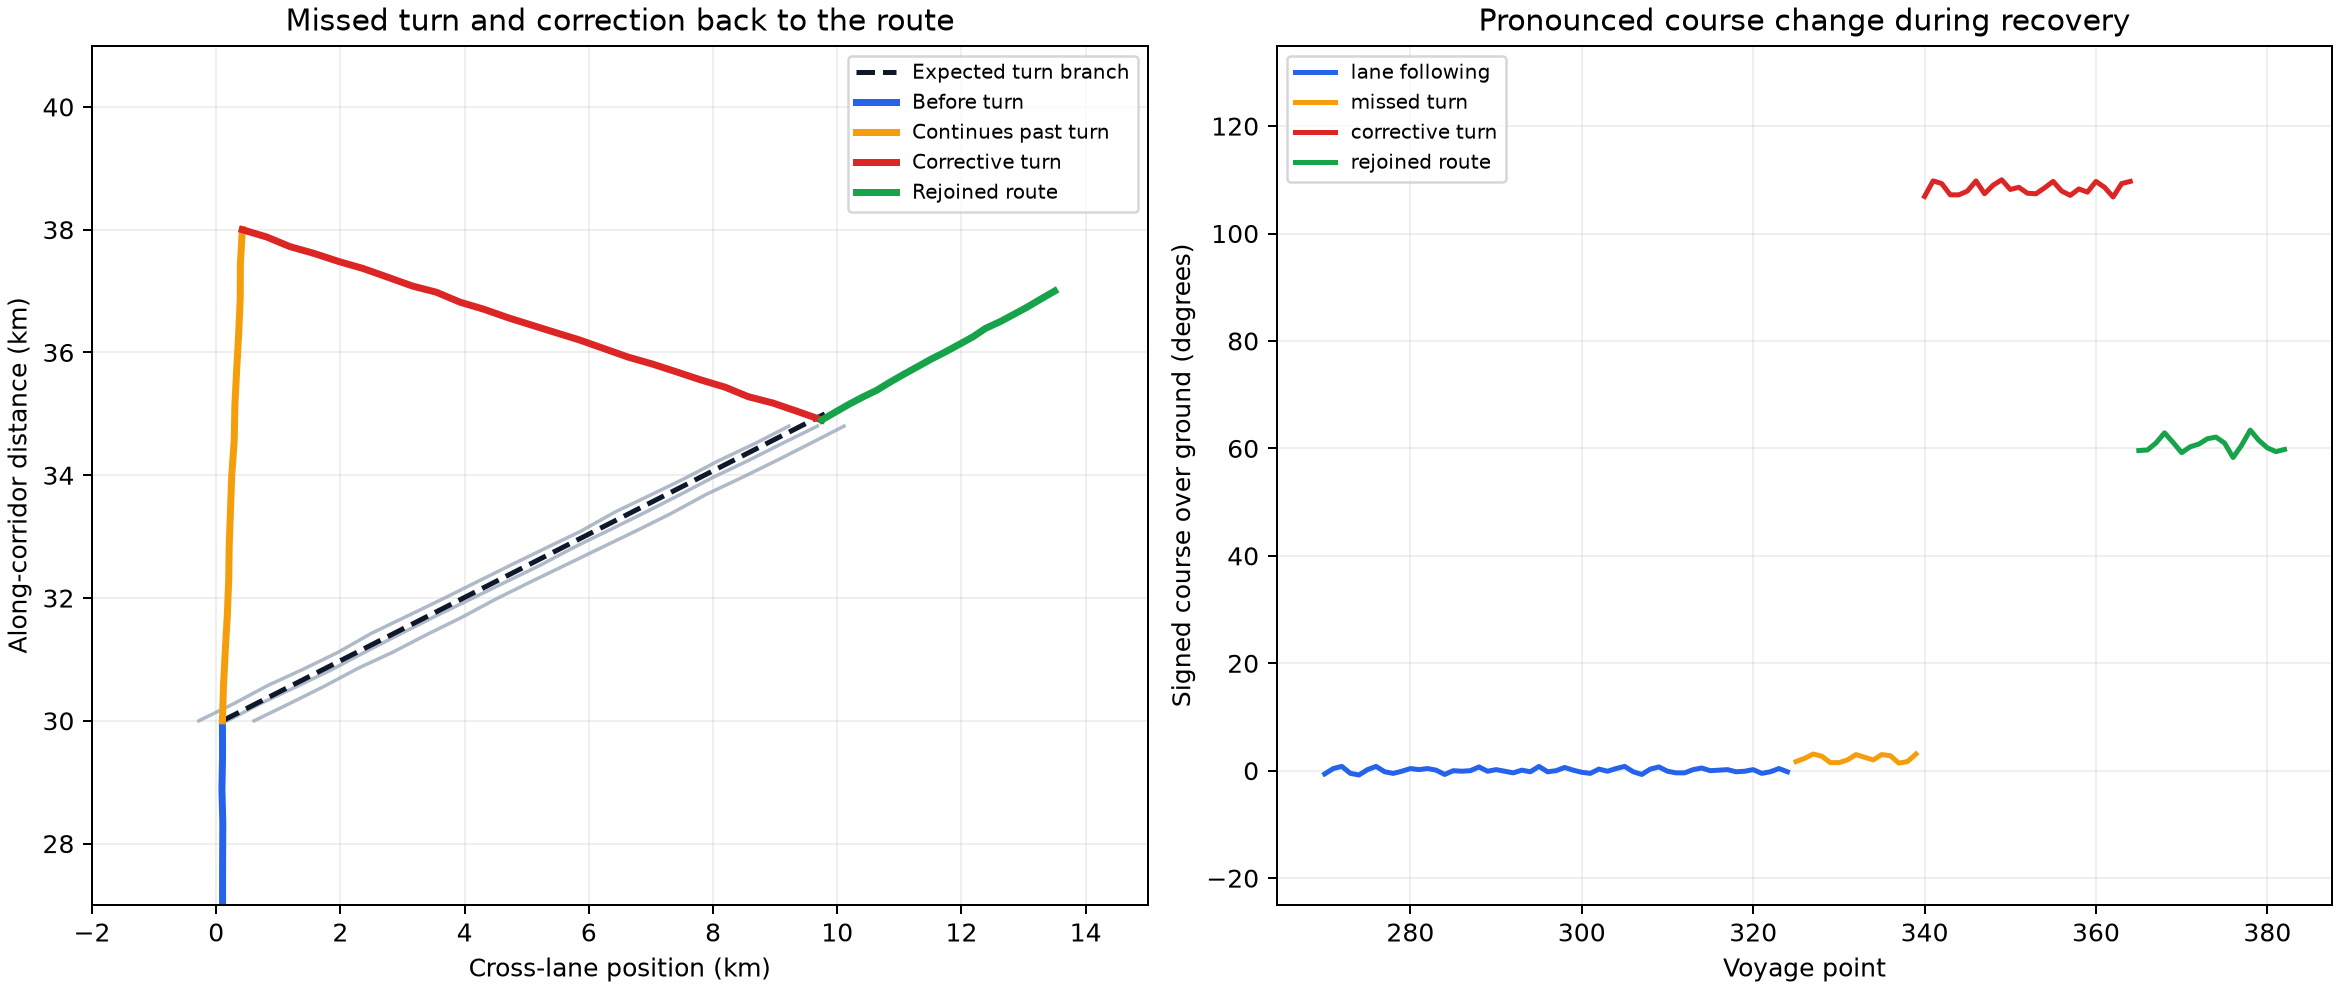

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df[d.traffic_role.eq('target_vessel')]; print(d.groupby('movement_phase')[['x_km','y_km','cog']].agg(['first','last','median'])); plt.plot(d.x_km,d.y_km); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/missed_turn_recovery.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (3 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "route_recovery",
  "insight": "The vessel continues beyond the typical turning point without making the expected course change, then performs a pronounced corrective turn to rejoin the established shipping route.",
  "insight_value": {
    "missed_turn_end_y_km": 38,
    "corrective_turn_end_x_km": 9.75
  },
  "plot": {
    "plot_type": "route_recovery",
    "title": "Missed Turn and Corrective Recovery",
    "file": "visualizations/missed_turn_recovery.png",
    "description": "The expected turn branch is dashed; the target vessel's overshoot and corrective segment are shown separately."
  },
  "question": "Does the vessel make the expected turn at the usual point, and if not, how does it recover?",
  "actionable_insight": "Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df[d.traffic_role.eq('target_vessel')]; print(d.groupby('movement_phase')[['x_km','y_km','cog']].agg(['first','last','median'])); plt.plot(d.x_km,d.y_km); plt.show()",
  "difficulty_level": 3,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "gps_position",
    "course_over_ground"
  ]
}

### **Question 3**: Does any part of the target vessel's voyage cross the dominant shipping flow rather than follow it?

#### Analysis action

Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.

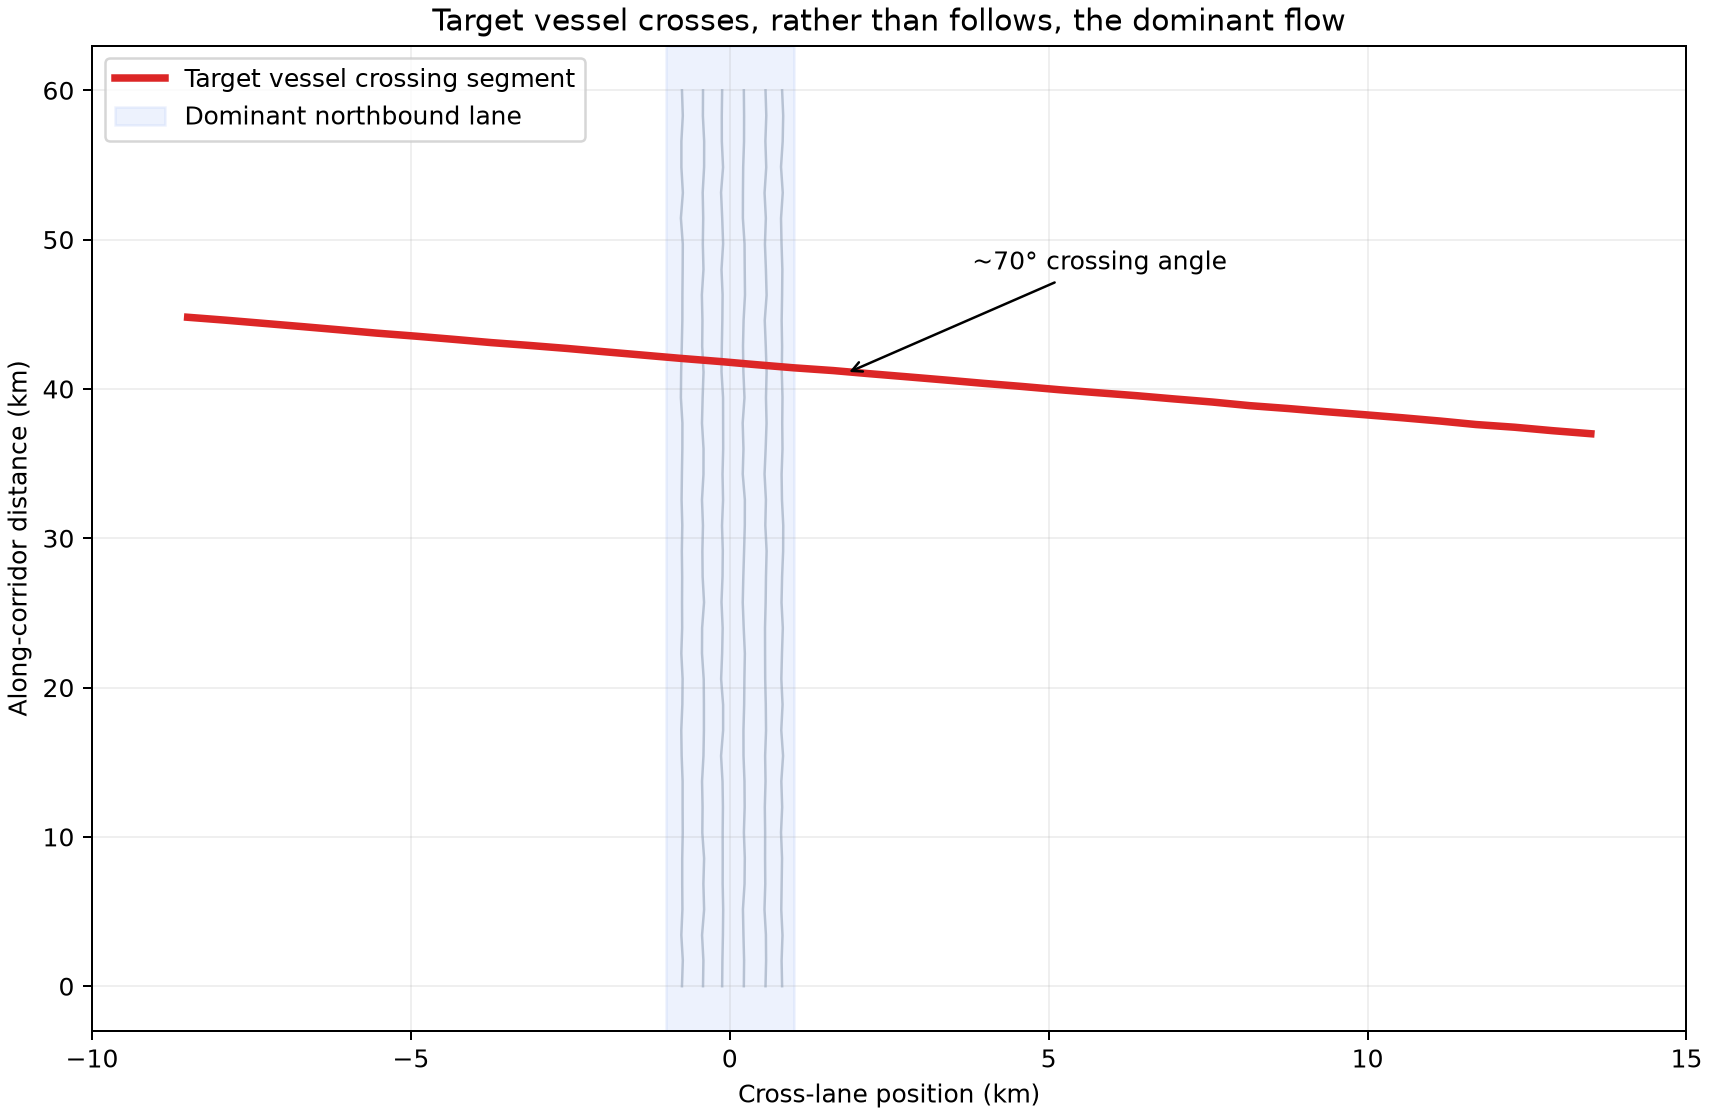

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
d=df.copy(); q=d[(d.traffic_role.eq('target_vessel')) & (d.movement_phase.eq('crossing_flow'))]; print(q[['x_km','y_km','cog']].describe()); plt.plot(q.x_km,q.y_km,color='red'); plt.show()
# Display the ground-truth visualization for this question.
from IPython.display import Image, SVG, display
display(Image(filename="visualizations/crossing_flow_angle.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Low (2 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "crossing_behavior",
  "insight": "Rather than travelling along the dominant traffic corridor, the vessel crosses the main shipping flow at a large angle, producing a movement pattern clearly different from ordinary lane-following traffic.",
  "insight_value": {
    "crossing_angle_degrees": 70,
    "crossing_segment_points": 38
  },
  "plot": {
    "plot_type": "crossing_behavior",
    "title": "Large-Angle Crossing of the Main Flow",
    "file": "visualizations/crossing_flow_angle.png",
    "description": "The red target-vessel segment is shown against the gray northbound commercial traffic lanes."
  },
  "question": "Does any part of the target vessel's voyage cross the dominant shipping flow rather than follow it?",
  "actionable_insight": "Inspect the event sequence, locations, and operating intervals together rather than treating each trip independently.",
  "code": "import pandas as pd\nimport matplotlib.pyplot as plt\nd=df.copy(); q=d[(d.traffic_role.eq('target_vessel')) & (d.movement_phase.eq('crossing_flow'))]; print(q[['x_km','y_km','cog']].describe()); plt.plot(q.x_km,q.y_km,color='red'); plt.show()",
  "difficulty_level": 2,
  "difficulty_label": "low",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "gps_position"
  ]
}

### Summary of Findings (Flag 5)

The target vessel follows the principal commercial lane for much of the voyage, but misses an expected turn, executes a visible corrective maneuver to rejoin the established branch, and later crosses the principal traffic flow at a large angle. These three phases distinguish it from ordinary lane-following traffic.